# BizBridge — Real Georgia Forms ML Training (HackATL 2026)

**Complete Colab workflow:** upload `bizbridge_dataset.zip` generated from your local `ml/data` folder → reconcile `inventory.csv` → OCR → audit labels → train a **real-data-only** classifier → group-disjoint evaluation → extract candidate fields → test document readiness against **human-verified** rules → export model and reports.

**No synthetic training fallback.** This is an experimental prototype, **not** a production-ready compliance or legal decision system. Eleven blank PDFs cannot establish accuracy on completed forms. The two E-Verify/SAVE affidavits have label `license_supporting_document`, not `business_license`.

Run cells **top to bottom**. Colab CPU runtime is fine. Keep sensitive completed applications out of public repos and Colab unless you have authorization.

**Updated version:** fixes Windows backslash ZIP entries and aligns imported PDF paths with `inventory.csv`. No synthetic fallback.


## 0 — Install packages and initialize paths

In [ ]:
%pip -q install pandas numpy scikit-learn pymupdf pillow pytesseract joblib matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 24.1 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
import pandas as pd, numpy as np, json, re, shutil, zipfile, subprocess, hashlib, datetime
from IPython.display import display
ROOT = Path('/content/bizbridge')
RAW = ROOT/'data'/'raw'
ANNOT = ROOT/'data'/'annotations'
OUT = ROOT/'artifacts'
for d in (RAW,ANNOT,OUT): d.mkdir(parents=True, exist_ok=True)
SEED=42
print('Workspace:',ROOT)


Workspace: /content/bizbridge


## 1 — Upload your local ZIP

In Windows PowerShell (inside `C:\Users\Simmi\HackATL`), run:

```powershell
Compress-Archive -Path ml\data -DestinationPath ml\bizbridge_dataset.zip -Force
```

Upload **`bizbridge_dataset.zip`** below. It should contain `data/raw/...` and `data/annotations/inventory.csv`. If you restart your Colab session, upload it again. **Do not upload private completed forms.**

**Important:** You only need to upload the ZIP once per Colab runtime. Run from the first setup cell through the upload and inventory cells in order; do not rerun the upload after successful extraction. ZIPs created by Windows PowerShell are supported.


In [ ]:
# UPLOAD: Handles Windows-created ZIPs containing backslashes in filenames.
from pathlib import Path, PurePosixPath
from google.colab import files
import zipfile, shutil, stat

uploaded = files.upload()
zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
if len(zip_names) != 1:
    raise ValueError('Select exactly one file: bizbridge_dataset.zip')

# ROOT/RAW/ANNOT are defined in the setup cell.
base = ROOT.resolve()
count = 0
with zipfile.ZipFile(zip_names[0]) as archive:
    for entry in archive.infolist():
        # PowerShell may store backslashes as literal ZIP filename characters.
        normalized = entry.filename.replace('\\', '/')
        parts = PurePosixPath(normalized).parts
        if (not parts or '..' in parts or normalized.startswith('/')
                or any(':' in component for component in parts)):
            raise ValueError('Unsafe archive entry: ' + entry.filename)
        mode = entry.external_attr >> 16
        if stat.S_IFMT(mode) == stat.S_IFLNK:
            raise ValueError('Symlink rejected: ' + entry.filename)
        if entry.is_dir() or normalized.endswith('/'):
            continue
        # Copy only data/raw and data/annotations; ignore unrelated entries.
        if 'raw' in parts:
            idx = parts.index('raw')
            target = RAW.joinpath(*parts[idx+1:]).resolve()
            allowed_root = RAW.resolve()
        elif 'annotations' in parts:
            idx = parts.index('annotations')
            target = ANNOT.joinpath(*parts[idx+1:]).resolve()
            allowed_root = ANNOT.resolve()
        else:
            continue
        if not target.is_relative_to(allowed_root) or target == allowed_root:
            raise ValueError('Unsafe extraction target: ' + entry.filename)
        target.parent.mkdir(parents=True, exist_ok=True)
        with archive.open(entry) as src, target.open('wb') as dst:
            shutil.copyfileobj(src, dst)
        count += 1

print('Extracted files:', count)
print('Imported PDFs:', len(list(RAW.rglob('*.pdf'))))
print('Inventory exists:', (ANNOT / 'inventory.csv').is_file())
assert (ANNOT / 'inventory.csv').is_file(), 'The ZIP must include annotations/inventory.csv'
assert list(RAW.rglob('*.pdf')), 'No PDF forms found; check the ZIP contents.'


Saving bizbridge_dataset.zip to bizbridge_dataset.zip
Extracted files: 12
Imported PDFs: 11
Inventory exists: True


## 2 — Normalize local Windows/GitHub inventory paths and audit labels

In [ ]:
# INVENTORY: Resolve Windows / GitHub paths to the actual extracted PDFs.
import pandas as pd
from pathlib import Path, PurePosixPath
from IPython.display import display

INV_PATH = ANNOT / 'inventory.csv'
if not INV_PATH.is_file():
    raise FileNotFoundError('Run the upload cell first: inventory.csv is missing.')
source_df = pd.read_csv(INV_PATH, encoding='utf-8-sig').fillna('')
required = {'file_path', 'document_type', 'template_group'}
if not required.issubset(source_df.columns):
    raise ValueError(f'Missing inventory columns: {required - set(source_df.columns)}')
if 'filename' not in source_df:
    source_df['filename'] = source_df['file_path'].map(lambda p: str(p).replace('\\','/').split('/')[-1])

def resolve_file(p):
    normalized = str(p).replace('\\', '/')
    parts = PurePosixPath(normalized).parts
    if 'raw' not in parts:
        raise ValueError(f'Inventory path must contain raw/: {p}')
    # Ignore preceding local prefixes (e.g. ml/data/raw), preserve category/subdirs.
    relative_parts = parts[parts.index('raw') + 1:]
    if not relative_parts or '..' in relative_parts:
        raise ValueError(f'Invalid inventory path: {p}')
    result = RAW.joinpath(*relative_parts).resolve()
    if not result.is_relative_to(RAW.resolve()):
        raise ValueError(f'Unsafe inventory path: {p}')
    return result

source_df['colab_path'] = source_df['file_path'].map(lambda p: str(resolve_file(p)))
source_df['exists'] = source_df['colab_path'].map(lambda p: Path(p).is_file())
print('Inventory rows:', len(source_df), '| PDFs found:', len(list(RAW.rglob('*.pdf'))))
print(source_df['document_type'].value_counts().to_string())
display(source_df[['filename','document_type','template_group','exists']])
if not source_df['exists'].all():
    missing = source_df.loc[~source_df['exists'], 'file_path'].tolist()
    raise FileNotFoundError(f'Inventory references missing PDFs: {missing}')
if source_df['colab_path'].duplicated().any():
    raise ValueError('Duplicate document paths in inventory')
print('SUCCESS: All 11 documents are accessible.' if len(source_df)==11 else 'SUCCESS: All inventoried documents are accessible.')
print('Review category labels manually; folder names are not verified ground truth.')


Inventory rows: 11 | PDFs found: 11
document_type
business_registration          3
food_service_permit            3
tax_document                   3
license_supporting_document    2


,filename,document_type,template_group,exists
0,Annual Registration (CD 940).pdf,business_registration,Annual Registration (CD 940),True
1,Articles of Organization for LLC (CD 030).pdf,business_registration,Articles of Organization for LLC (CD 030),True
2,Limited Liability Company (CD 231).pdf,business_registration,Limited Liability Company (CD 231),True
3,EnvHealthFoodGA_DPH_Mobile_Food_Unit_Permit_Ap...,food_service_permit,EnvHealthFoodGA_DPH_Mobile_Food_Unit_Permit_Ap...,True
4,EnvHealth_Food_TempFoodServiceVendorApplicatio...,food_service_permit,EnvHealth_Food_TempFoodServiceVendorApplication,True
5,Expedited Authorization Permitting Application...,food_service_permit,Expedited Authorization Permitting Application...,True
6,atlanta_everify_affidavit.pdf,license_supporting_document,atlanta_everify_affidavit,True
7,atlanta_save_affidavit.pdf,license_supporting_document,atlanta_save_affidavit,True
8,rd1061_tax_authorization.pdf,tax_document,rd1061_tax_authorization,True
9,st3_sales_tax_return.pdf,tax_document,st3_sales_tax_return,True


SUCCESS: All 11 documents are accessible.
Review category labels manually; folder names are not verified ground truth.


### Label review and document-family rules

* The 2 Atlanta E-Verify/SAVE affidavits belong to `license_supporting_document`, **not** actual issued licenses.
* A form **application** is not an issued permit or proof of compliance. The class names below denote **form subject**, not permit validity.
* `template_group` must be the same for all filled/scanned versions of an identical government template. The script initially uses filename stems; manually fix this when collecting variants.
* Keep `source_url` as the official government source page or preferably the exact document link, and confirm redistribution rules.

**Current training subset:** 3 business registration forms, 3 food-service forms, and 3 tax forms; other categories remain stored but are excluded until they have enough independent examples.

In [ ]:
TRAIN_CLASSES=['business_registration','food_service_permit','tax_document']
use_df=source_df[source_df.document_type.isin(TRAIN_CLASSES)].copy()
print('Training candidates:',len(use_df))
print(use_df.groupby('document_type').agg(documents=('file_path','size'),template_groups=('template_group','nunique')))
for label in TRAIN_CLASSES:
    k=use_df.loc[use_df.document_type==label,'template_group'].nunique()
    if k<3:raise ValueError(f'{label}: only {k} independent template groups. Need >=3 for separate train/val/test.')


Training candidates: 9
                       documents  template_groups
document_type                                    
business_registration          3                3
food_service_permit            3                3
tax_document                   3                3


## 3 — OCR + PDF text extraction (original PDF, then OCR if necessary)

In [ ]:
if not shutil.which('tesseract'):
    subprocess.run(['apt-get','update','-qq'],check=True,stdout=subprocess.DEVNULL)
    subprocess.run(['apt-get','install','-y','-qq','tesseract-ocr'],check=True,stdout=subprocess.DEVNULL)
print('OCR engine:',shutil.which('tesseract'))
import fitz, pytesseract
from PIL import Image

def extract_document_text(path,max_pages=12,minimum_native_chars=50):
    path=Path(path);suffix=path.suffix.lower()
    if suffix=='.txt':return path.read_text(encoding='utf-8',errors='replace')
    if suffix=='.pdf':
        parts=[]
        with fitz.open(path) as pdf:
            for page_idx in range(min(len(pdf),max_pages)):
                page=pdf[page_idx]
                text=page.get_text('text',sort=True)
                if len(text.strip())<minimum_native_chars:
                    pix=page.get_pixmap(matrix=fitz.Matrix(2,2),alpha=False)
                    img=Image.frombytes('RGB',(pix.width,pix.height),pix.samples)
                    text=pytesseract.image_to_string(img)
                parts.append(text)
        return '\n'.join(parts)
    if suffix in {'.png','.jpg','.jpeg','.tif','.tiff'}:
        with Image.open(path) as img:return pytesseract.image_to_string(img)
    raise ValueError('Unsupported file: '+str(path))

records=[]
for r in use_df.itertuples(index=False):
    try:
        txt=extract_document_text(r.colab_path)
        records.append({'file_path':r.file_path,'colab_path':r.colab_path,'filename':r.filename,
                        'document_type':r.document_type,'template_group':str(r.template_group),
                        'text':txt,'text_chars':len(txt.strip()),'read_error':''})
    except Exception as exc:
        records.append({'file_path':r.file_path,'colab_path':r.colab_path,'filename':r.filename,
                        'document_type':r.document_type,'template_group':str(r.template_group),
                        'text':'','text_chars':0,'read_error':str(exc)})
docs=pd.DataFrame(records)
display(docs[['filename','document_type','text_chars','read_error']])
if (docs.text_chars<30).any():
    raise ValueError('Some documents have <30 readable characters. Repair/OCR those before training.')
print('REAL PDFs successfully read:',len(docs))


OCR engine: /usr/bin/tesseract


,filename,document_type,text_chars,read_error
0,Annual Registration (CD 940).pdf,business_registration,1437,
1,Articles of Organization for LLC (CD 030).pdf,business_registration,4898,
2,Limited Liability Company (CD 231).pdf,business_registration,3568,
3,EnvHealthFoodGA_DPH_Mobile_Food_Unit_Permit_Ap...,food_service_permit,9163,
4,EnvHealth_Food_TempFoodServiceVendorApplicatio...,food_service_permit,10661,
5,Expedited Authorization Permitting Application...,food_service_permit,5384,
6,rd1061_tax_authorization.pdf,tax_document,11793,
7,st3_sales_tax_return.pdf,tax_document,26132,
8,st5_tax_exemption.pdf,tax_document,5814,


REAL PDFs successfully read: 9


## 4 — Transparent group-disjoint train / validation / test

Exactly 3 independent forms per category means only **one form per category** in each of train, validation, and test. That is enough to prove the pipeline works but not to estimate accuracy reliably. No artificial copies or synthetic text are introduced.

Keep this test set untouched while you improve the model. When you collect more independent templates, retrain and evaluate again.

In [ ]:
rng=np.random.default_rng(SEED)
assignments={}
for label,g in docs.groupby('document_type'):
    groups=sorted(g.template_group.unique().tolist())
    rng.shuffle(groups)
    if len(groups)<3:raise ValueError(f'{label} has <3 distinct templates')
    for group in groups[:1]:assignments[(label,group)]='test'
    for group in groups[1:2]:assignments[(label,group)]='val'
    for group in groups[2:]:assignments[(label,group)]='train'
docs['split']=docs.apply(lambda r:assignments[(r.document_type,r.template_group)],axis=1)
train_df=docs[docs.split=='train'].copy();val_df=docs[docs.split=='val'].copy();test_df=docs[docs.split=='test'].copy()
assert not (set(zip(train_df.document_type,train_df.template_group)) & set(zip(test_df.document_type,test_df.template_group)))
print(pd.crosstab(docs.document_type,docs.split))
display(docs[['filename','document_type','template_group','split']])
docs.drop(columns=['text']).to_csv(OUT/'dataset_manifest.csv',index=False)


split                  test  train  val
document_type                          
business_registration     1      1    1
food_service_permit       1      1    1
tax_document              1      1    1


,filename,document_type,template_group,split
0,Annual Registration (CD 940).pdf,business_registration,Annual Registration (CD 940),train
1,Articles of Organization for LLC (CD 030).pdf,business_registration,Articles of Organization for LLC (CD 030),val
2,Limited Liability Company (CD 231).pdf,business_registration,Limited Liability Company (CD 231),test
3,EnvHealthFoodGA_DPH_Mobile_Food_Unit_Permit_Ap...,food_service_permit,EnvHealthFoodGA_DPH_Mobile_Food_Unit_Permit_Ap...,test
4,EnvHealth_Food_TempFoodServiceVendorApplicatio...,food_service_permit,EnvHealth_Food_TempFoodServiceVendorApplication,train
5,Expedited Authorization Permitting Application...,food_service_permit,Expedited Authorization Permitting Application...,val
6,rd1061_tax_authorization.pdf,tax_document,rd1061_tax_authorization,train
7,st3_sales_tax_return.pdf,tax_document,st3_sales_tax_return,test
8,st5_tax_exemption.pdf,tax_document,st5_tax_exemption,val


## 5 — Train the baseline classifier on REAL Georgia PDF text

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model=Pipeline([
 ('tfidf',TfidfVectorizer(ngram_range=(1,2),sublinear_tf=True,max_features=25000)),
 ('clf',LogisticRegression(class_weight='balanced',max_iter=1500,random_state=SEED))
])
model.fit(train_df.text,train_df.document_type)
print('Trained with',len(train_df),'real forms, no synthetic fallback.')
val_pred=model.predict(val_df.text)
print('Validation macro F1:',round(f1_score(val_df.document_type,val_pred,average='macro',zero_division=0),3))
print(classification_report(val_df.document_type,val_pred,labels=TRAIN_CLASSES,zero_division=0))


Trained with 3 real forms, no synthetic fallback.
Validation macro F1: 1.0
                       precision    recall  f1-score   support

business_registration       1.00      1.00      1.00         1
  food_service_permit       1.00      1.00      1.00         1
         tax_document       1.00      1.00      1.00         1

             accuracy                           1.00         3
            macro avg       1.00      1.00      1.00         3
         weighted avg       1.00      1.00      1.00         3



## 6 — Held-out test evaluation (one-time assessment)

Holdout accuracy: 1.0
Holdout macro F1: 1.0
                       precision    recall  f1-score   support

business_registration       1.00      1.00      1.00         1
  food_service_permit       1.00      1.00      1.00         1
         tax_document       1.00      1.00      1.00         1

             accuracy                           1.00         3
            macro avg       1.00      1.00      1.00         3
         weighted avg       1.00      1.00      1.00         3



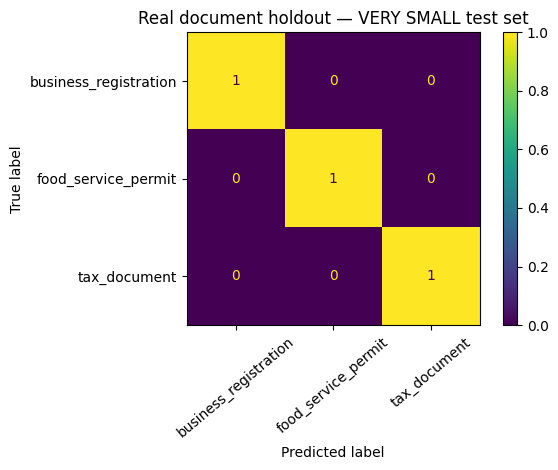

In [ ]:
test_pred=model.predict(test_df.text)
TEST_MACRO_F1=float(f1_score(test_df.document_type,test_pred,labels=TRAIN_CLASSES,average='macro',zero_division=0))
print('Holdout accuracy:',round(accuracy_score(test_df.document_type,test_pred),3))
print('Holdout macro F1:',round(TEST_MACRO_F1,3))
print(classification_report(test_df.document_type,test_pred,labels=TRAIN_CLASSES,zero_division=0))
ConfusionMatrixDisplay.from_predictions(test_df.document_type,test_pred,labels=TRAIN_CLASSES,xticks_rotation=40)
plt.title('Real document holdout — VERY SMALL test set')
plt.tight_layout();plt.savefig(OUT/'confusion_matrix.png',dpi=140);plt.show()
with open(OUT/'evaluation.json','w') as f:
    json.dump({'training_data':'real_Georgia_PDFs','synthetic_training':False,
     'n_train':len(train_df),'n_validation':len(val_df),'n_test':len(test_df),
     'holdout_macro_f1':TEST_MACRO_F1,
     'warning':'Only ~1 test form per class; unreliable estimate of generalization. Blank forms only.'},f,indent=2)


## 7 — Classify a document and flag uncertainty

In [ ]:
REVIEW_SCORE_THRESHOLD=0.65   # Heuristic only — not validated/calibrated!
def classify_text(text):
    scores=model.predict_proba([text])[0]
    rank=np.argsort(scores)[::-1]
    label=str(model.classes_[rank[0]]);score=float(scores[rank[0]])
    return {'predicted_form_category':label,'uncalibrated_model_score':round(score,4),
            'human_review_required':score<REVIEW_SCORE_THRESHOLD,
            'top_candidates':[{'category':str(model.classes_[i]),'score':round(float(scores[i]),4)} for i in rank[:3]],
            'not_an_issued_document_validation':True}
print(json.dumps(classify_text(test_df.iloc[0].text),indent=2))


{
  "predicted_form_category": "business_registration",
  "uncalibrated_model_score": 0.3698,
  "human_review_required": true,
  "top_candidates": [
    {
      "category": "business_registration",
      "score": 0.3698
    },
    {
      "category": "tax_document",
      "score": 0.3216
    },
    {
      "category": "food_service_permit",
      "score": 0.3086
    }
  ],
  "not_an_issued_document_validation": true
}


## 8 — Extract candidate fields (heuristics; **not** trained NER)

These are candidate strings from OCR, **not verified entity values**. Blank government forms usually include labels but no completed values, so this cannot prove autofill accuracy. Use permissioned, annotated filled-in examples later.

In [ ]:
DATE_RE=r'\b(?:20\d{2}[-/]\d{1,2}[-/]\d{1,2}|\d{1,2}[-/]\d{1,2}[-/]20\d{2})\b'
def extract_candidate_fields(text):
    patterns={
      'business_name':r'(?im)^\s*(?:legal business name|business name|entity name)\s*[:\-]\s*(.{2,90})$',
      'business_address':r'(?im)^\s*(?:business address|principal office address|street address)\s*[:\-]\s*(.{4,140})$',
      'document_identifier':r'(?im)\b(?:license|permit|certificate|policy)\s*(?:number|no\.?|#)\s*[:#\-]\s*([A-Z0-9-]{4,35})'
    }
    result={'dates_found':list(dict.fromkeys(re.findall(DATE_RE,text)))[:20]}
    for name,pat in patterns.items():
        m=re.search(pat,text)
        result[name]=m.group(1).strip() if m else None
    result['all_values_require_user_confirmation']=True
    return result

def analyze_document(path):
    text=extract_document_text(path)
    if not text.strip():return {'error':'No readable text','human_review_required':True}
    return {'filename':Path(path).name,'classification':classify_text(text),
            'candidate_fields':extract_candidate_fields(text),'compliance_status':'not_determined'}
sample=Path(test_df.iloc[0].colab_path)
print(json.dumps(analyze_document(sample),indent=2))


{
  "filename": "Limited Liability Company (CD 231).pdf",
  "classification": {
    "predicted_form_category": "business_registration",
    "uncalibrated_model_score": 0.3698,
    "human_review_required": true,
    "top_candidates": [
      {
        "category": "business_registration",
        "score": 0.3698
      },
      {
        "category": "tax_document",
        "score": 0.3216
      },
      {
        "category": "food_service_permit",
        "score": 0.3086
      }
    ],
    "not_an_issued_document_validation": true
  },
  "candidate_fields": {
    "dates_found": [],
    "business_name": null,
    "business_address": null,
    "document_identifier": null,
    "all_values_require_user_confirmation": true
  },
  "compliance_status": "not_determined"
}


## 9 — Compliance gap detection, dependencies, deadlines: **verified rules only**

`inventory.csv` labels example documents; it does **not** say which permits a real business needs. Build `verified_requirements.csv` from an official source, with jurisdiction, industry, applicability, prerequisites, date, and reviewer. This notebook creates a blank schema and **does not pretend that laws or deadlines are confirmed**.

The gap checker below works **only** when reviewed requirements exist. A missing uploaded file does not prove a business is legally noncompliant.

In [ ]:
RULE_COLUMNS=['requirement_id','jurisdiction','industry','business_type','requirement_name',
              'document_type','prerequisite_ids','deadline','official_source_url','verified_on','reviewed_by','status']
rules_path=ANNOT/'verified_requirements.csv'
if not rules_path.exists():pd.DataFrame(columns=RULE_COLUMNS).to_csv(rules_path,index=False)

def find_possible_document_gaps(jurisdiction,industry,business_type,uploaded_document_types):
    rules=pd.read_csv(rules_path).fillna('')
    if rules.empty:return {'status':'no_verified_rules_loaded','possible_gaps':[],
       'message':'A reviewer must populate official requirements before compliance checks are available.'}
    rules=rules[(rules.status=='verified') & (rules.jurisdiction==jurisdiction) &
                (rules.industry==industry) & (rules.business_type==business_type)]
    gaps=rules[~rules.document_type.isin(set(uploaded_document_types))]
    return {'status':'review_required','possible_gaps':gaps.to_dict(orient='records'),
            'disclaimer':'Missing uploads are not proof of noncompliance or permit validity.'}
print(find_possible_document_gaps('Atlanta, GA','restaurant','LLC',[]))


{'status': 'no_verified_rules_loaded', 'possible_gaps': [], 'message': 'A reviewer must populate official requirements before compliance checks are available.'}


## 10 — Official source grounding for a future AI copilot

Use links in government forms/inventory as **references for human review**, not as a trained legal model. For a chatbot: retrieve official passages, cite specific pages, store a `verified_on` timestamp, and abstain when no reviewed source supports an answer. Translation and form submission are **not implemented** in this training notebook.

In [ ]:
source_links=source_df[['document_type','source_url']].drop_duplicates().query("source_url != ''")
display(source_links)
print('To build RAG, annotate reviewed passages separately; do not train an LLM on the 11 PDFs.')


,document_type,source_url
0,business_registration,https://sos.ga.gov/page/georgia-business-forms
3,food_service_permit,https://dph.georgia.gov/environmental-health/f...
6,license_supporting_document,https://www.atlantaga.gov/government/departmen...
8,tax_document,https://dor.georgia.gov/


To build RAG, annotate reviewed passages separately; do not train an LLM on the 11 PDFs.


## 11 — Export classifier, metadata, and integration bundle

In [ ]:
import joblib, sklearn
model_path=OUT/'document_classifier.joblib'
joblib.dump(model,model_path)
metadata={
 'project':'BizBridge','date_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
 'model':'TF-IDF + LogisticRegression','trained_on':'real Georgia government PDF text',
 'synthetic_training':False,'labels':list(map(str,model.classes_)),
 'training_documents':len(train_df),'validation_documents':len(val_df),'test_documents':len(test_df),
 'test_macro_f1':TEST_MACRO_F1,'model_score_calibrated':False,
 'scikit_learn_version':sklearn.__version__,
 'limitations':['Only 9 real training/evaluation candidates from 3 classes',
  'No issued-permit validity determination','Blank forms are not filled-in documents',
  'Form-field extraction is heuristic','No verified legal requirements are bundled by default']}
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2))
zip_out=OUT/'bizbridge_ml_bundle.zip'
with zipfile.ZipFile(zip_out,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in (model_path,OUT/'metadata.json',OUT/'evaluation.json',OUT/'dataset_manifest.csv',OUT/'confusion_matrix.png'):
        z.write(f,arcname=f.name)
print('Ready:',zip_out,'size (KB)',round(zip_out.stat().st_size/1024,1))


Ready: /content/bizbridge/artifacts/bizbridge_ml_bundle.zip size (KB) 80.5


In [ ]:
from google.colab import files
files.download(str(zip_out))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12 — Integration for your backend teammate

Place `document_classifier.joblib` in `ml/models/` and commit `metadata.json`, `evaluation.json`, and your notebook in `ml/evaluation/` and `ml/notebooks/`. **Only load trusted `.joblib` files.** The classifier accepts OCR-extracted **text**, not a PDF directly.

```python
import joblib
model = joblib.load('ml/models/document_classifier.joblib')  # trusted file only
pred = model.predict(['OCR text from uploaded document'])[0]
```

Recommended API return: `predicted_form_category`, `uncalibrated_model_score`, `human_review_required`, `candidate_fields`, `compliance_status='not_determined'`. Do not call a *form classification* an approval or license validation.

**Next real improvements:** collect more independent forms per class (and actual authorized, filled-in samples), manually label field values, measure OCR error, evaluate whole unseen templates, calibrate uncertainty on representative samples, verify official rule CSV, add multilingual access and RAG.
